# IMPORTING THE NECCESSARY LIBRARIES

In [1]:
#Libraries for exploratory data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Scikit learn for preprocessing and model building
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge, Lasso
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report, mean_absolute_error,mean_squared_error,accuracy_score

#Neural Network
from tensorflow import keras

#Pipeline and transformers
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.ensemble import VotingClassifier
from sklearn.compose import ColumnTransformer

# Exploratory Data Analysis

In [3]:
#reading the dataset into sheet format
df = pd.read_csv("Crop_recommendation.csv")

In [8]:
df.shape

(2200, 8)

In [4]:
df.isnull().sum() #checking for missing values in the columns

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info() #Brief info of the dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [9]:
df.describe().a #statistical summary of the dataframe

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [10]:
df.nunique() #checking for the number of unique values in the columns of each dataframe

,0
N,137
P,117
K,73
temperature,2200
humidity,2200
ph,2200
rainfall,2200
label,22


In [ ]:
df["label"].unique() #checking for unique values in the 'Label' column

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [ ]:
df["label"].value_counts() #The number of unique values in the 'Label' column
#Equal sampling

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

In [ ]:
df[df["label"] == 'rice'].head()  #Dataframe for the rice 'Label' portion

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [15]:
from sklearn.preprocessing import LabelEncoder
#Encoding
encode = LabelEncoder()
df["label"] = encode.fit_transform(df["label"])

In [20]:
df.label.unique()

array([20, 11,  3,  9, 18, 13, 14,  2, 10, 19,  1, 12,  7, 21, 15,  0, 16,
       17,  4,  6,  8,  5])

In [18]:
num_columns = df.select_dtypes(exclude="object") #getting only the numerical portion of the data

In [64]:
def HeatMap(frame,title):
  corr = frame.select_dtypes(exclude="object").corr() #Getting the correlation of the numerical columns
  plt.figure(figsize=(7,4))
  sns.heatmap(corr.corr(),annot=True)
  plt.title(f"{title}\n",fontsize=15)
  plt.show()

In [87]:
df[df.label==0]

,N,P,K,temperature,humidity,ph,rainfall,label
1500,24,128,196,22.750888,90.694892,5.521467,110.431786,0
1501,7,144,197,23.849401,94.348150,6.133221,114.051249,0
1502,14,128,205,22.608010,94.589006,6.226290,116.039659,0
1503,8,120,201,21.186674,91.134357,6.321152,122.233323,0
1504,20,129,201,23.410447,91.699133,5.587906,116.077793,0
...,...,...,...,...,...,...,...,...
1595,40,120,197,23.805938,92.488795,5.889481,119.633555,0
1596,25,132,198,22.319441,90.851744,5.732758,100.117344,0
1597,31,137,196,22.144641,93.825674,6.400321,120.631078,0
1598,36,144,196,23.651676,94.505288,6.496934,115.361127,0


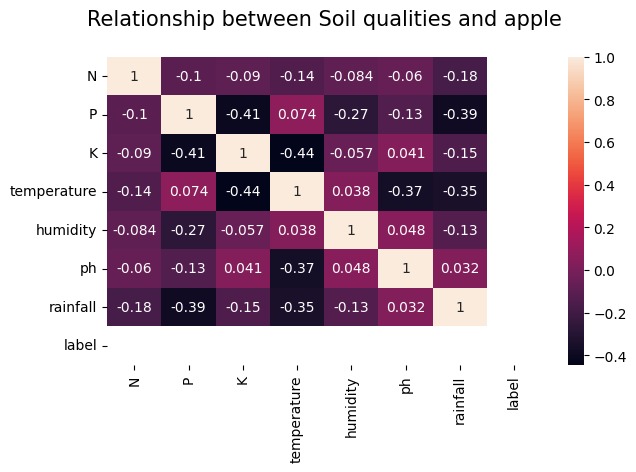

In [65]:
HeatMap(df[df.label==0],f"Relationship between Soil qualities and {encode.inverse_transform([0])[0]}")

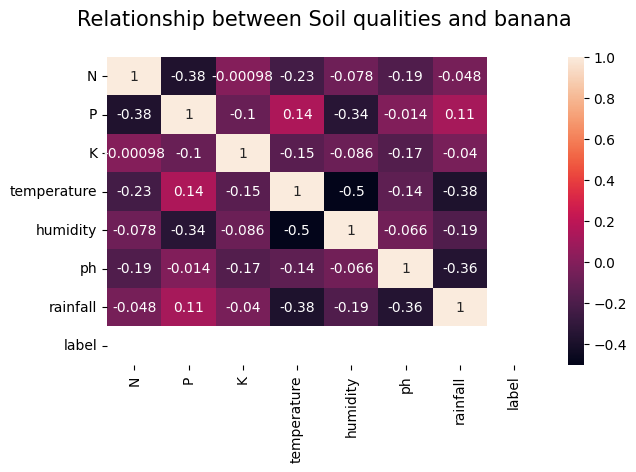

In [66]:
HeatMap(df[df.label==1],f"Relationship between Soil qualities and {encode.inverse_transform([1])[0]}")

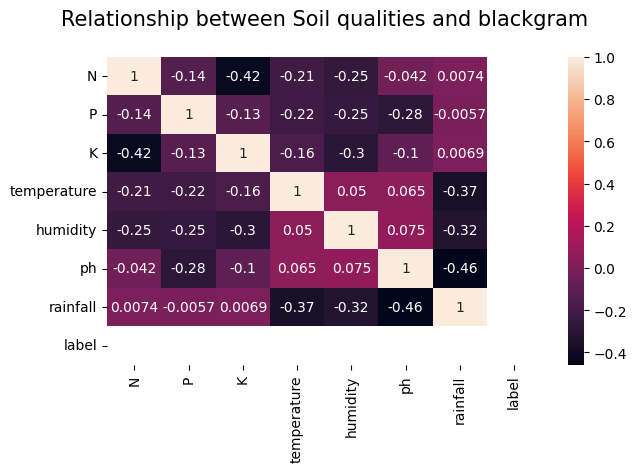

In [67]:
HeatMap(df[df.label==2],f"Relationship between Soil qualities and {encode.inverse_transform([2])[0]}")

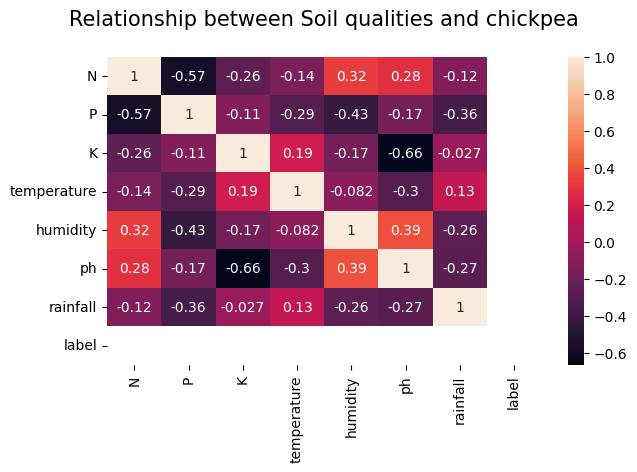

In [68]:
HeatMap(df[df.label==3],f"Relationship between Soil qualities and {encode.inverse_transform([3])[0]}")

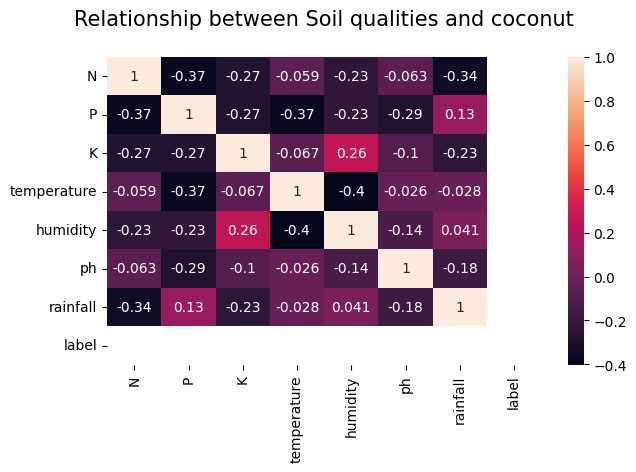

In [69]:
HeatMap(df[df.label==4],f"Relationship between Soil qualities and {encode.inverse_transform([4])[0]}")

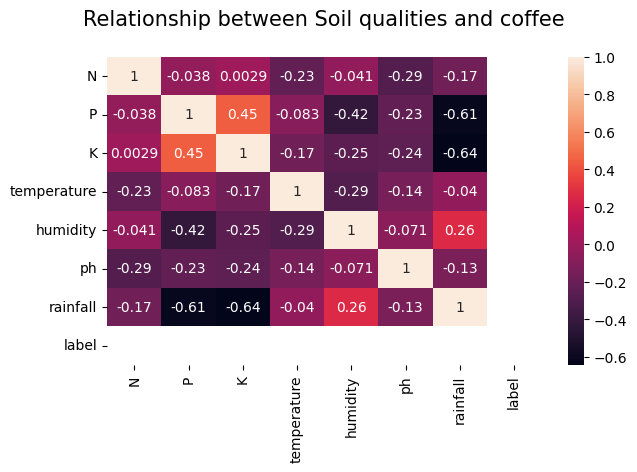

In [70]:
HeatMap(df[df.label==5],f"Relationship between Soil qualities and {encode.inverse_transform([5])[0]}")

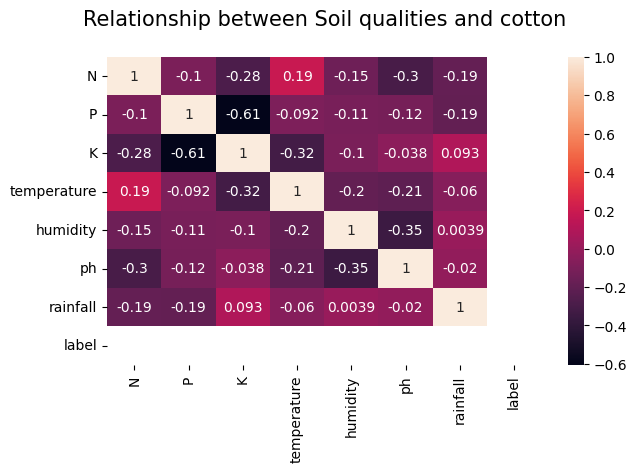

In [71]:
HeatMap(df[df.label==6],f"Relationship between Soil qualities and {encode.inverse_transform([6])[0]}")

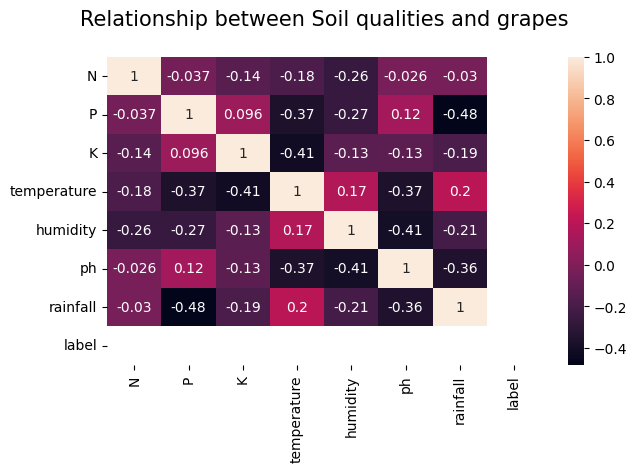

In [72]:
HeatMap(df[df.label==7],f"Relationship between Soil qualities and {encode.inverse_transform([7])[0]}")

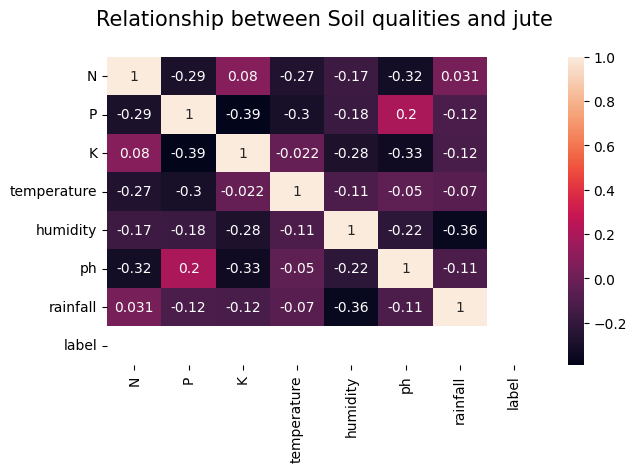

In [73]:
HeatMap(df[df.label==8],f"Relationship between Soil qualities and {encode.inverse_transform([8])[0]}")

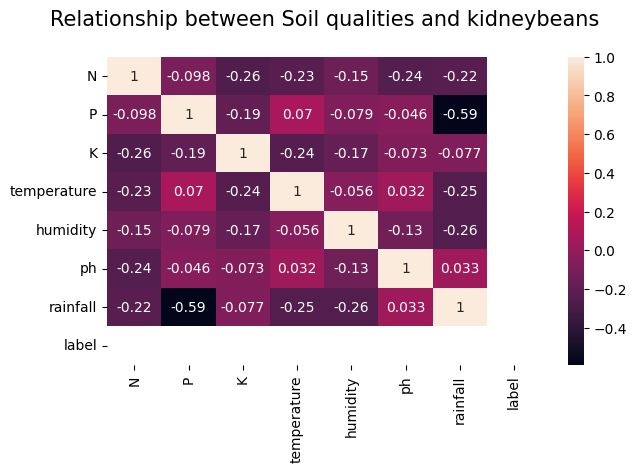

In [74]:
HeatMap(df[df.label==9],f"Relationship between Soil qualities and {encode.inverse_transform([9])[0]}")

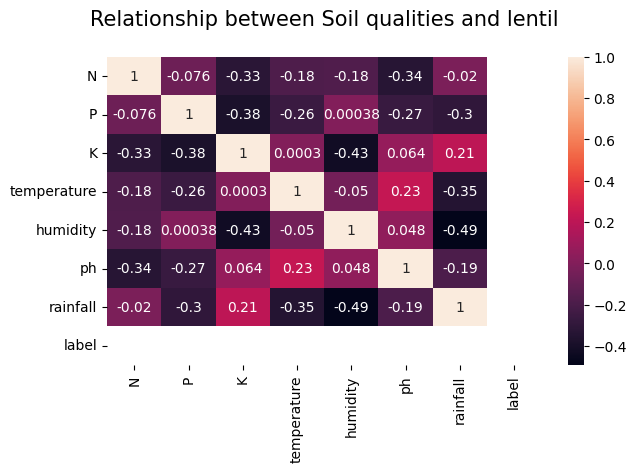

In [75]:
HeatMap(df[df.label==10],f"Relationship between Soil qualities and {encode.inverse_transform([10])[0]}")

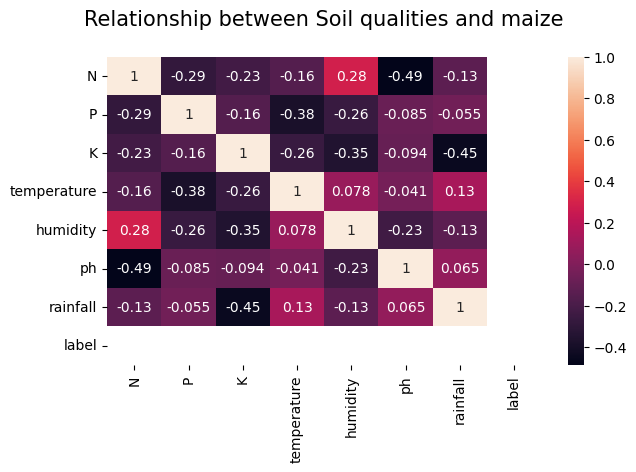

In [76]:
HeatMap(df[df.label==11],f"Relationship between Soil qualities and {encode.inverse_transform([11])[0]}")

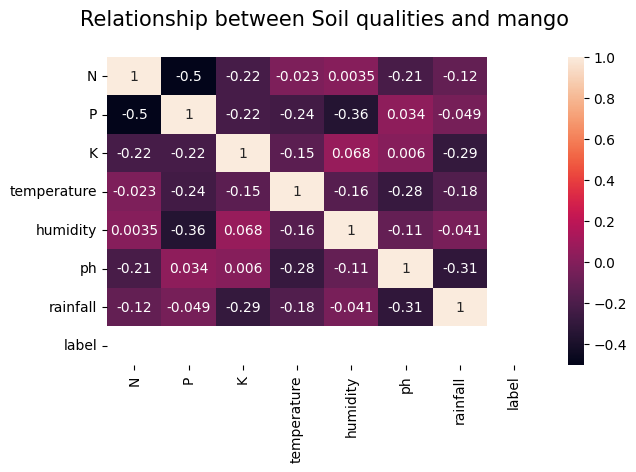

In [77]:
HeatMap(df[df.label==12],f"Relationship between Soil qualities and {encode.inverse_transform([12])[0]}")

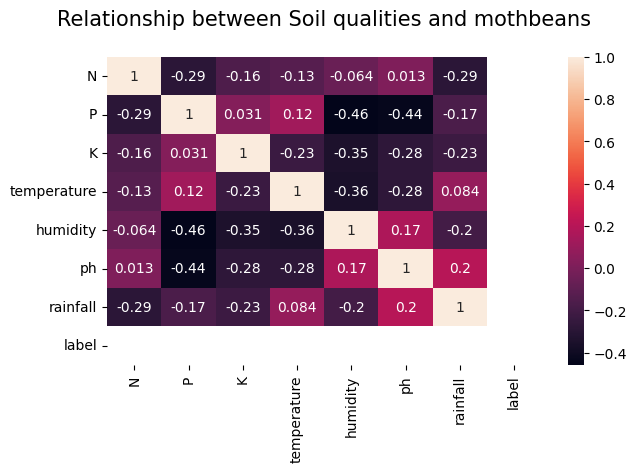

In [78]:
HeatMap(df[df.label==13],f"Relationship between Soil qualities and {encode.inverse_transform([13])[0]}")

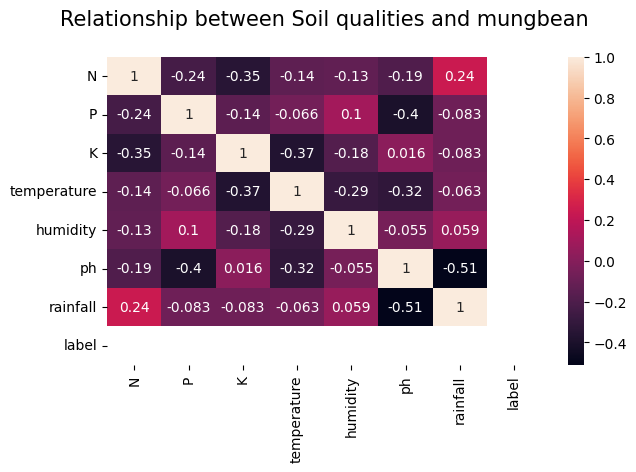

In [79]:
HeatMap(df[df.label==14],f"Relationship between Soil qualities and {encode.inverse_transform([14])[0]}")

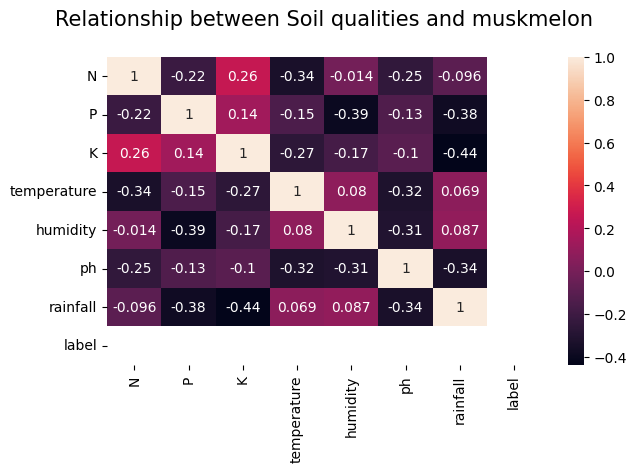

In [80]:
HeatMap(df[df.label==15],f"Relationship between Soil qualities and {encode.inverse_transform([15])[0]}")

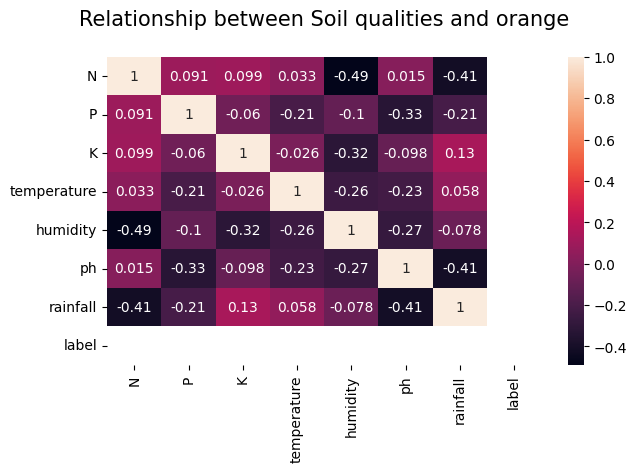

In [81]:
HeatMap(df[df.label==16],f"Relationship between Soil qualities and {encode.inverse_transform([16])[0]}")

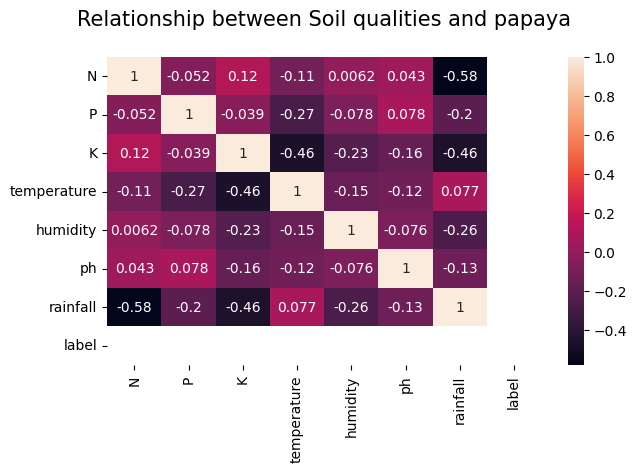

In [82]:
HeatMap(df[df.label==17],f"Relationship between Soil qualities and {encode.inverse_transform([17])[0]}")

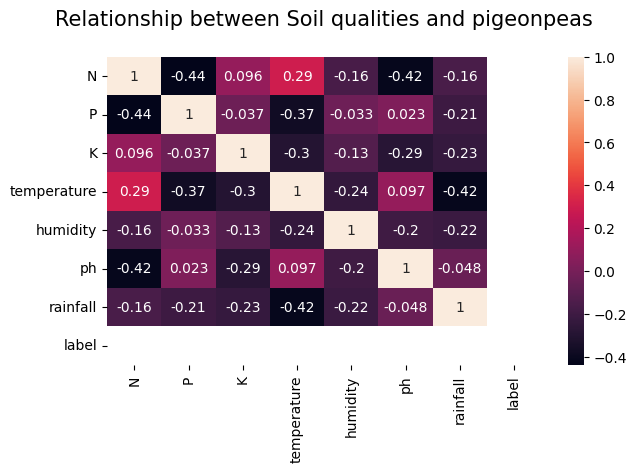

In [83]:
HeatMap(df[df.label==18],f"Relationship between Soil qualities and {encode.inverse_transform([18])[0]}")

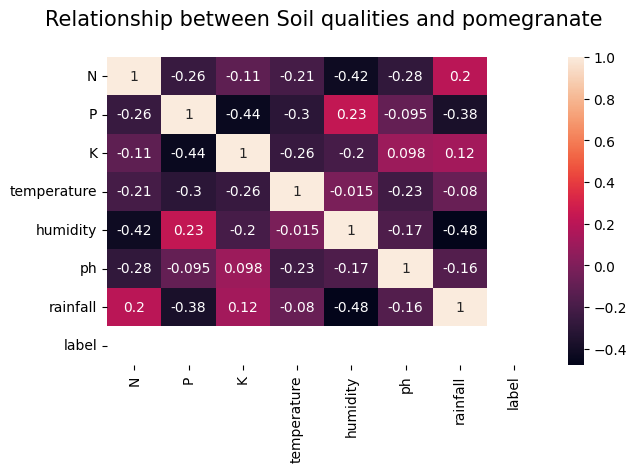

In [84]:
HeatMap(df[df.label==19],f"Relationship between Soil qualities and {encode.inverse_transform([19])[0]}")

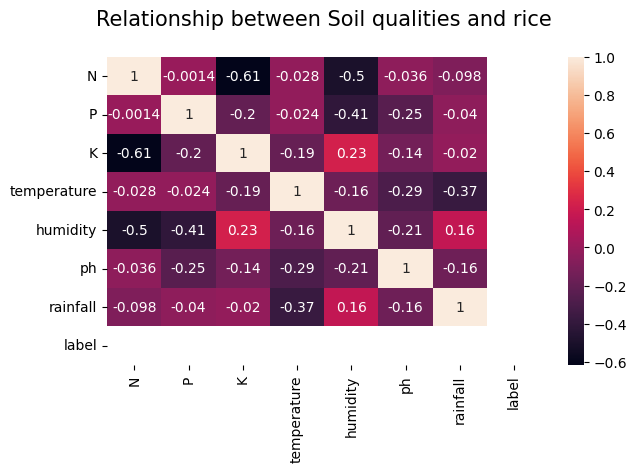

In [85]:
HeatMap(df[df.label==20],f"Relationship between Soil qualities and {encode.inverse_transform([20])[0]}")

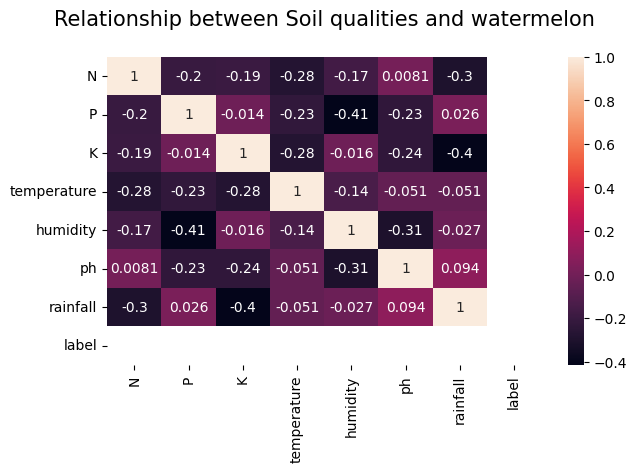

In [86]:
HeatMap(df[df.label==21],f"Relationship between Soil qualities and {encode.inverse_transform([21])[0]}")

# Outliers Removal

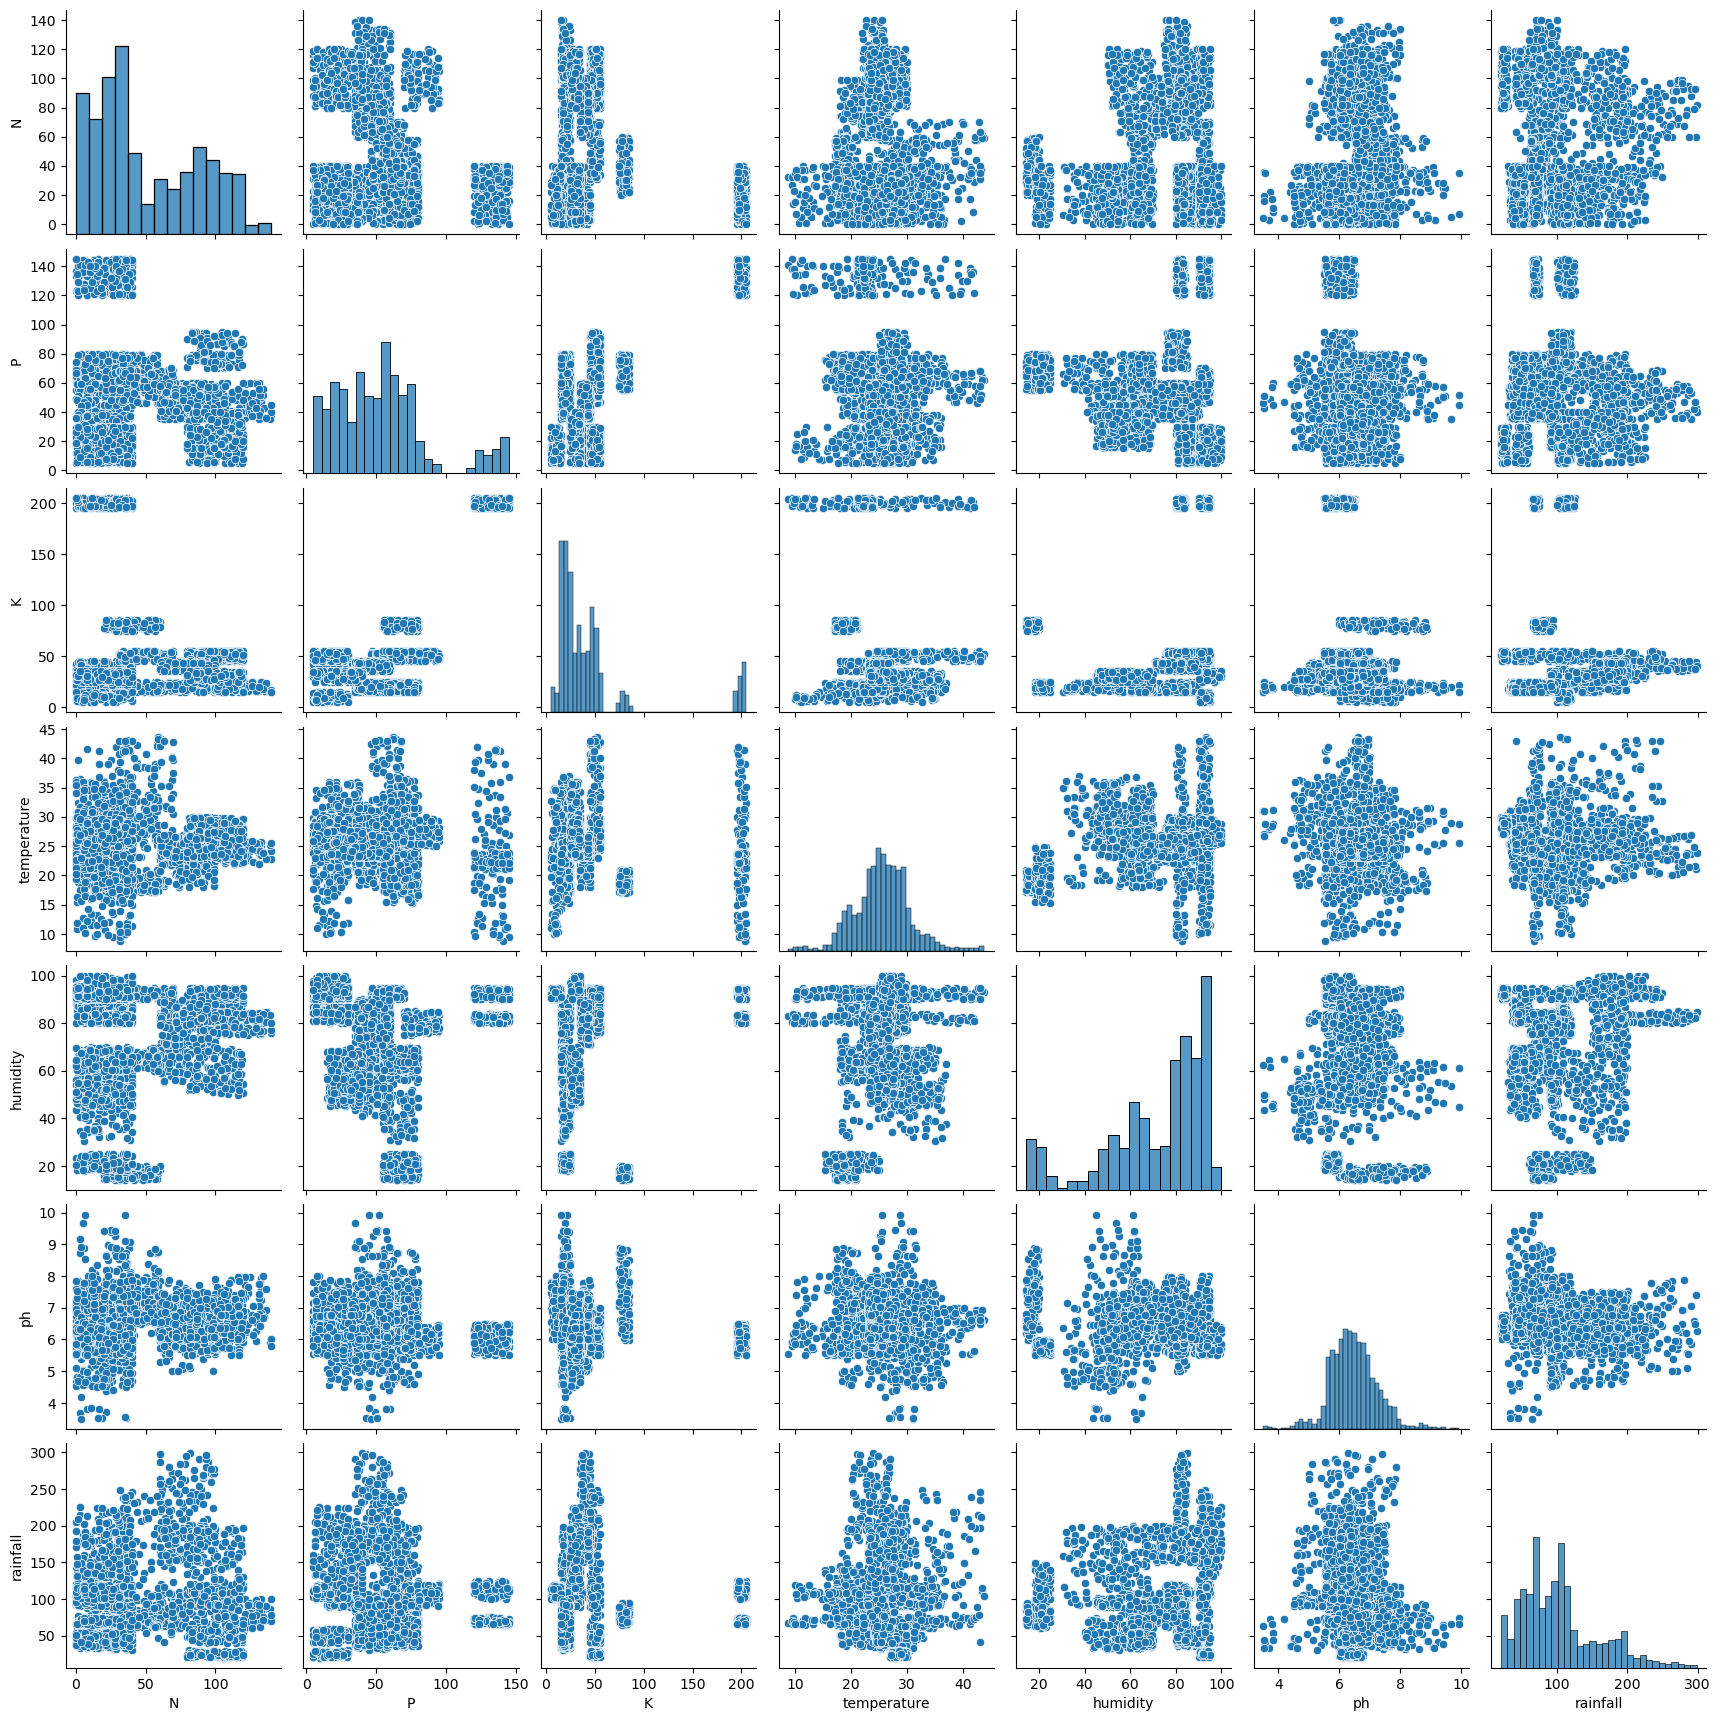

In [ ]:
sns.pairplot(num_columns) #A pair plot to check for the relationship between columns and to find
                          # And to help find outliers in our dataset
plt.show()

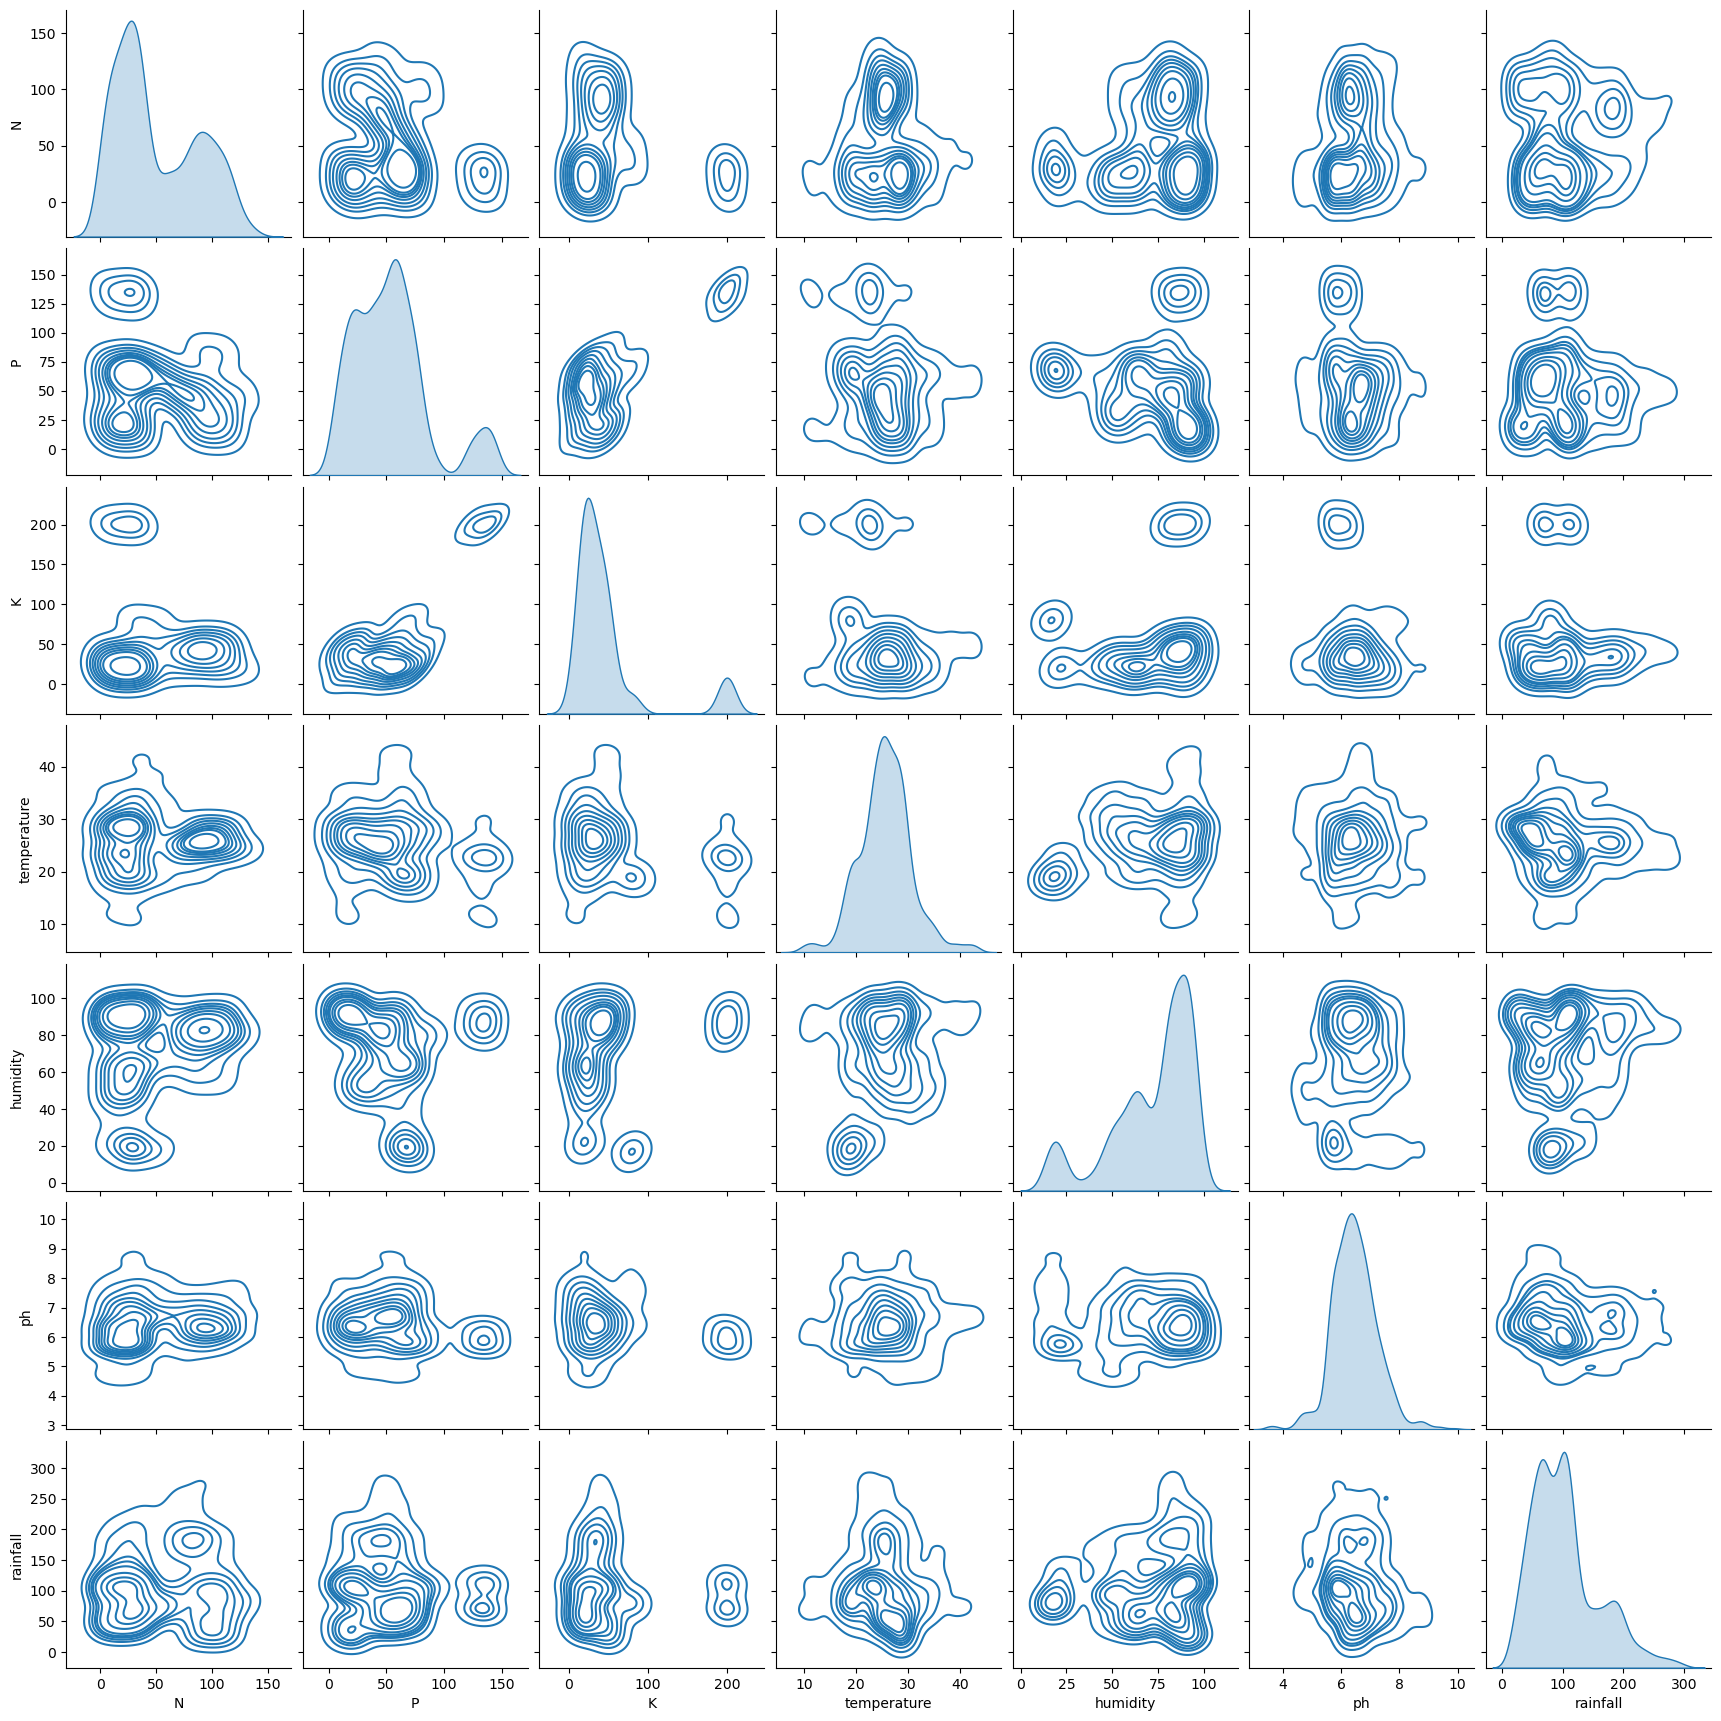

In [ ]:
sns.pairplot(df,kind='kde') # Shows the relationship and the distribution
                            #which basically shows the probabilly density of the columns in the dataframe
plt.savefig("Farm.jpg")
plt.show()

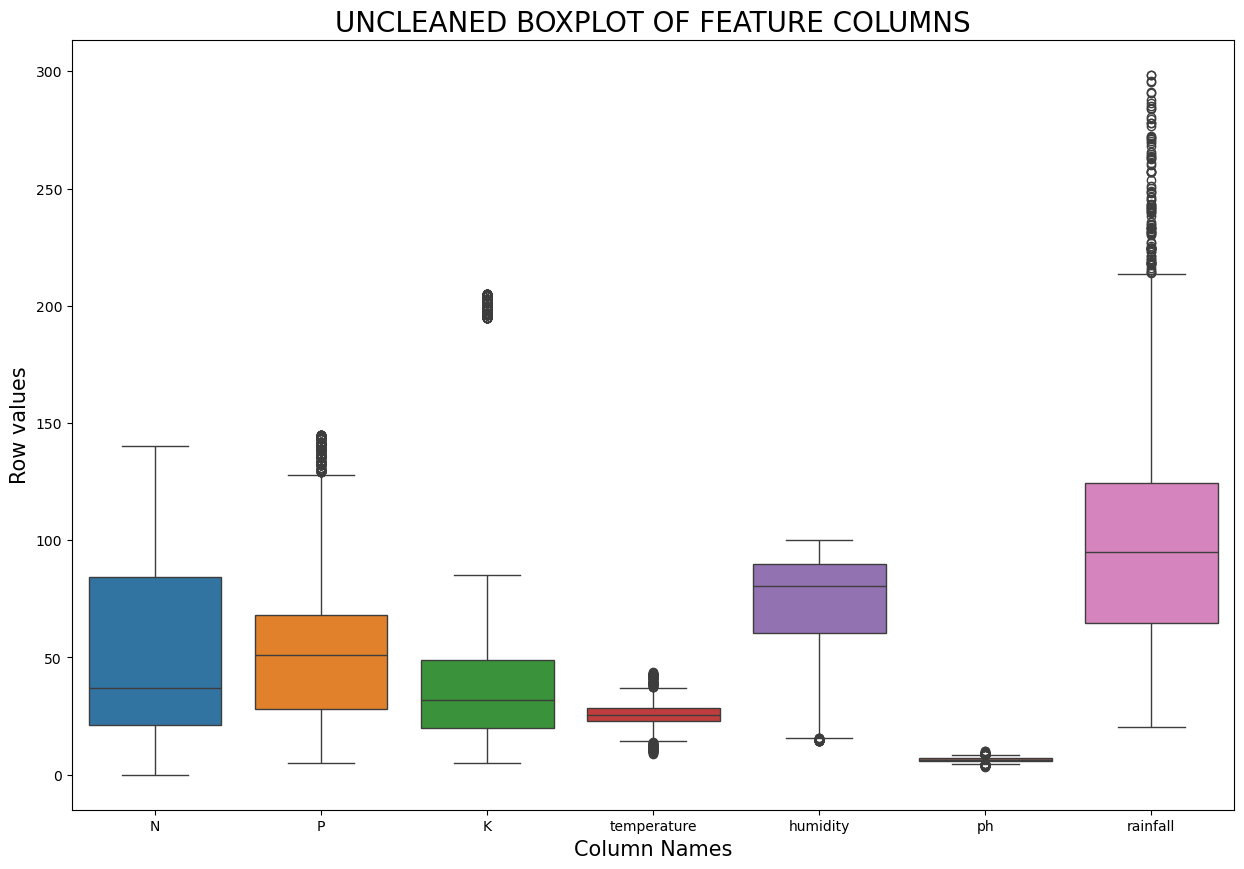

In [ ]:
#Boxplot for identifying outliers
plt.figure(figsize=(15,10))
sns.boxplot(num_columns)
plt.title("UNCLEANED BOXPLOT OF FEATURE COLUMNS",fontsize=20)
plt.xlabel("Column Names",fontsize=15)
plt.ylabel("Row values",fontsize=15)
plt.show()

### Using IQR to remove outliers from P,K,temperature,humidity ,ph, rainfall

### Clean Phosphorus(P)

In [ ]:
df["P"].unique()[:4] #Checking for the first four values in the Phosphorus(P) column

array([42, 58, 55, 35], dtype=int64)

In [ ]:
Q1p,Q3p = df.P.quantile([0.25,0.75]) #Getting the 25% and 75% percentile of the P column

In [ ]:
IQRp = (Q3p - Q1p) # Interquartile of the P column

In [ ]:
#The lower and Upper limits of the P column
lower_limitp = (Q1p - 1.5*IQRp)
upper_limitp = (Q3p + 1.5*IQRp)

In [ ]:
p_outliers = df[(df.P < lower_limitp) | (df.P > upper_limitp)] #Outliers less than lower limits and greater than the Upper lim
p_outliers.sample(5)

,N,P,K,temperature,humidity,ph,rainfall,label
1278,39,129,203,34.389225,83.183928,5.863997,71.030016,grapes
1564,17,136,196,23.871923,90.499390,5.882156,103.054809,apple
1226,13,132,203,23.601154,82.483370,6.423217,73.239018,grapes
1204,24,131,196,22.032962,83.743728,5.732454,65.344408,grapes
1578,14,139,197,21.724845,92.839756,6.056530,121.696176,apple


In [ ]:
mask_p = ((df.P > lower_limitp) & (df.P < upper_limitp)) #Getting the good data and dropping the outliers

### Clean Potassium(K)

In [ ]:
df["K"].unique()[:4] #Checking for the first four values in the Clean Potassium(K) column

array([43, 41, 44, 40], dtype=int64)

In [ ]:
Q1k,Q3k = df.K.quantile([0.24,0.75]) #Getting the 25% and 75% percentile of the K column
IQRk = (Q3k - Q1k) # Interquartile of the K column

#The lower and Upper limits of the K column
lower_limitk = (Q1k - 1.5*IQRk)
upper_limitk = (Q3k + 1.5*IQRk)

mask_k = ((df.K > lower_limitk) & (df.K < upper_limitk)) #Getting the good data and dropping the outliers

### Outliers removal from temperature using IQR

In [ ]:
Q1t,Q3t = df.temperature.quantile([0.24,0.75])

In [ ]:
IQRt = (Q3t - Q1t)

In [ ]:
lower_limitT = (Q1t - 1.5*IQRt)
upper_limitT = (Q3t + 1.5*IQRt)


In [ ]:
mask_temp = ((df.temperature > lower_limitT) & (df.temperature < upper_limitT))

### Clean Humidity

In [ ]:
Q1hum,Q3hum = df.humidity.quantile([0.24,0.75])
IQRhum = (Q3hum - Q1hum)
lower_limithum = (Q1hum - 1.5*IQRhum)
upper_limithum = (Q3hum + 1.5*IQRhum)
mask_hum = ((df.humidity > lower_limithum) & (df.humidity < upper_limithum))

In [ ]:
humidity_outliers = df[((df.humidity < lower_limithum) | (df.humidity > upper_limithum))]
humidity_outliers

,N,P,K,temperature,humidity,ph,rainfall,label


### Clean PH

In [ ]:
Q1ph,Q3ph = df.ph.quantile([0.24,0.75])
IQRph = (Q3ph - Q1ph)
lower_limitph = (Q1ph - 1.5*IQRph)
upper_limitph = (Q3ph + 1.5*IQRph)
mask_ph = ((df.ph > lower_limitph) & (df.ph < upper_limitph))

### Clean Rainfall

In [ ]:
Q1rain,Q3rain = df.rainfall.quantile([0.24,0.75])
IQRrain = (Q3rain - Q1rain)
lower_limitrain = (Q1rain - 1.5*IQRrain)
upper_limitrain = (Q3rain + 1.5*IQRrain)
mask_rain = ((df.rainfall > lower_limitrain) & (df.rainfall < upper_limitrain))

In [ ]:
#Getting the cleaned portion of the data and dropping the outliers

df = df[mask_p & mask_temp & mask_hum & mask_ph & mask_rain & mask_k]

##### DISPLAYING THE CLEANED BOXPLOT OF EACH COLUMN IN THE DATASET

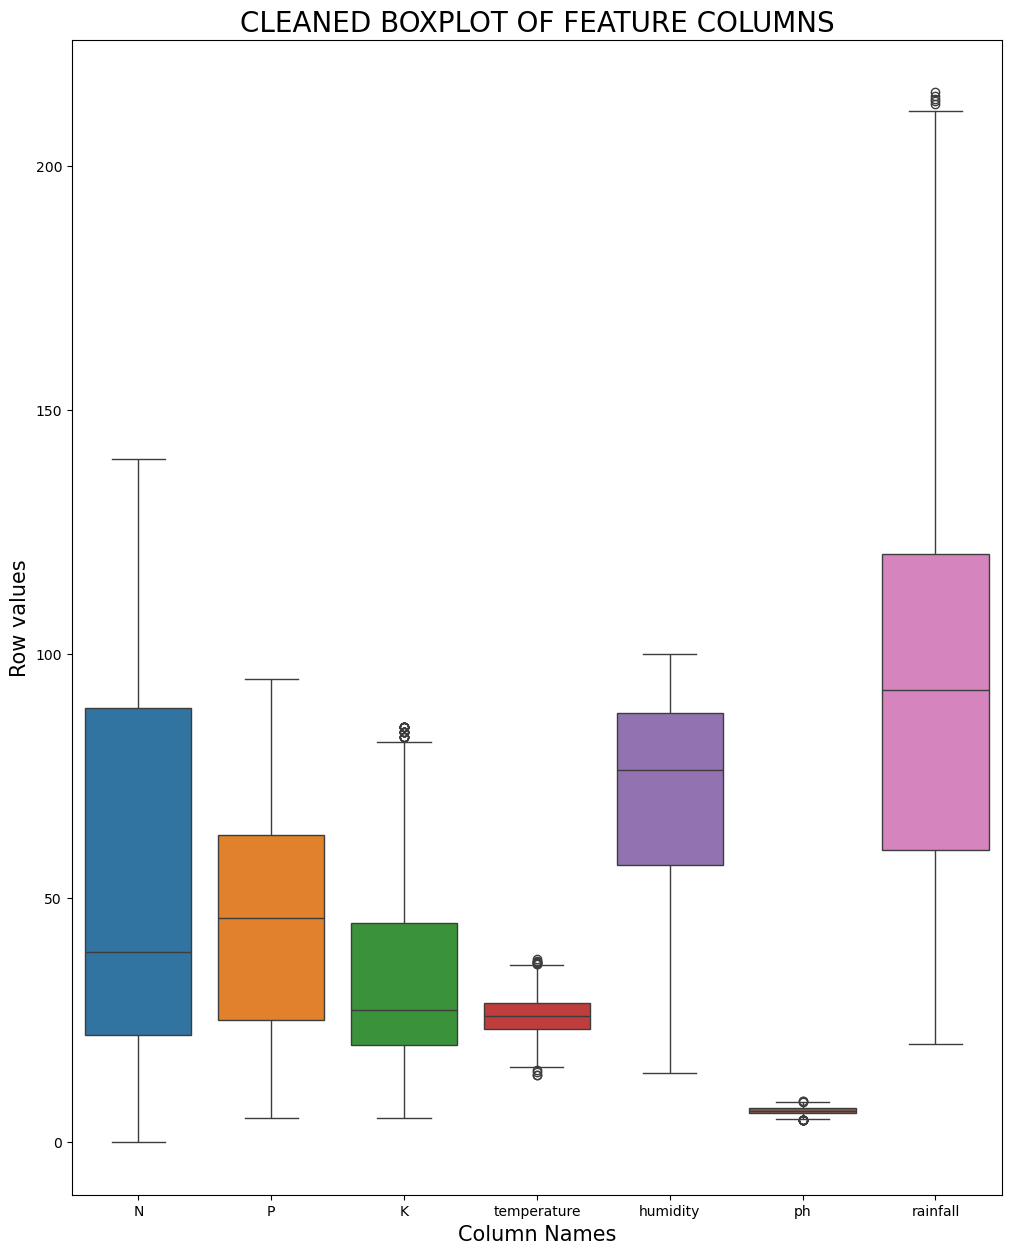

In [ ]:

plt.figure(figsize=(12,15))
sns.boxplot(df)
plt.title("CLEANED BOXPLOT OF FEATURE COLUMNS",fontsize=20)
plt.xlabel("Column Names",fontsize=15)
plt.ylabel("Row values",fontsize=15)
plt.show()

##### VISUALISATION TO IDENTIFY THE TOTAL PERCENTAGE OF EACH CROP IN A PIE CHART FROMAT

In [ ]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [ ]:
df.label.unique() #Our target columns unique values

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'watermelon', 'muskmelon', 'orange', 'papaya',
       'coconut', 'cotton', 'jute', 'coffee'], dtype=object)

In [ ]:
df.label.nunique() # Total number of the unique values

20

In [ ]:
pie_crops = df.groupby("label")["label"].value_counts() #Getting the sum of each unique value in the Label column

In [ ]:
labels= ['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'watermelon', 'muskmelon', 'orange', 'papaya',
       'coconut', 'cotton', 'jute', 'coffee'] # labels for the pie chart


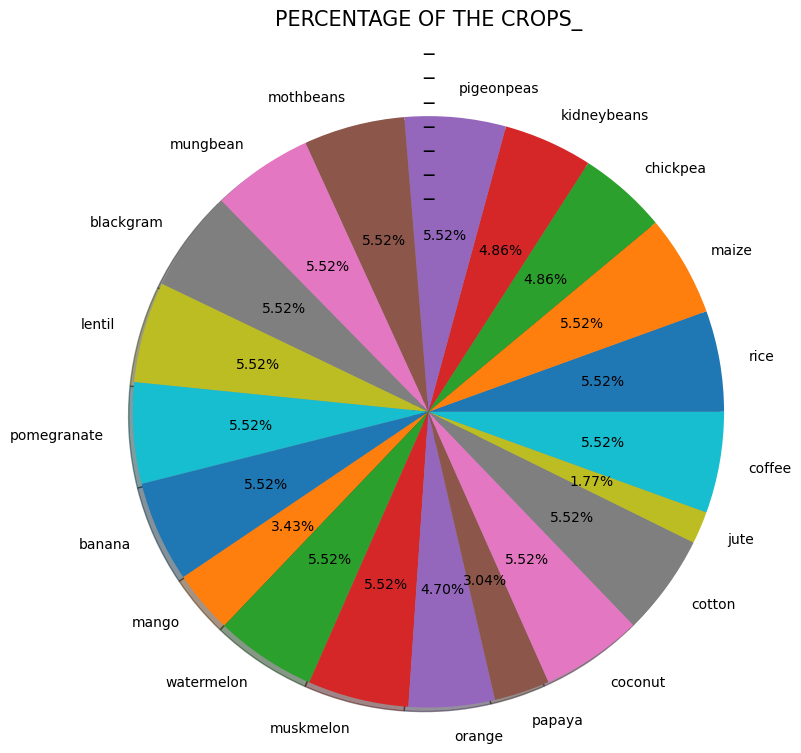

In [ ]:
plt.pie(pie_crops,autopct="%.2f%%",radius=2,labels=labels,shadow=True)
plt.title("PERCENTAGE OF THE CROPS"+'_\n'*8,fontsize=15)
plt.show()

## Building the Machine Learning model

In [ ]:
#Dividing the dataframe into Feature columns and Targe column
X = df.drop("label",axis=1)
y = df.label

###### Dividing the data into training(70%) set, validating(15%) and testing(15%) datasets

In [ ]:
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.3,random_state=30)

In [ ]:
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=25)

In [ ]:
num_columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'] #storing the numerical columns in a num_columns

###### NUMERICAL PIPELINE FOR FILLING NAN VALUES AND SCALING THE NUMERICAL COLUMNS

In [ ]:

numerical_pipe = Pipeline(steps=[
    ("impute",SimpleImputer(strategy='mean')),
    ("scale",StandardScaler())


])

###### TRANFORMING THE NUMERICAL COLUMNS USING A COLUMN TRANSFORMER

In [ ]:
transformer = ColumnTransformer(transformers=[
    ("num_pipe",numerical_pipe,num_columns)
],
    remainder='drop',
    n_jobs=-1
)

###### USING THE VOTING REGRESSOR TO COMBINE DIFFERENT ML ALGORITHMS TO GET THE BEST PERFORMING RESULTS

In [ ]:
voting = VotingClassifier(estimators=[
    ("XGB",XGBClassifier()),
    ("Rforest",RandomForestClassifier(n_estimators=100,)),
    ("GBoost",GradientBoostingClassifier(n_estimators=100)),
    ("Dtree",DecisionTreeClassifier()),
    ("GNB",GaussianNB()),
    ("AdaBoost",AdaBoostClassifier())



],
    voting='soft'

                        )

###### CREATING A MAKE PIPELINE TO PASS THE TRANSFORMER AND THE VOTING ALGORITHM

In [ ]:
mk_model = make_pipeline(transformer,voting)

In [ ]:
print(f"\t\tTHE PIPELINE FOR DATA PREPROCESSING AND MODEL TRAINING\n"+'_'*80)
mk_model.fit(X_train,y_train) #Traing the model using the training data

		THE PIPELINE FOR DATA PREPROCESSING AND MODEL TRAINING
________________________________________________________________________________


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('num_pipe',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['N', 'P', 'K', 'temperature',
                                                   'humidity', 'ph',
                                                   'rainfall'])])),
                ('votingclassifier',
                 VotingClassifier(estimators=[('XGB',
                                               XGBClassifier(base_score=None,
                                                             booster=None,
                                                             callbacks=None,
                                                             colsample_byle...
                                                             max_leaves=None,
                                                             min_child_weight=None,
                                                             missing=nan,
                                                             monotone_constraints=None,
                                                             multi_strategy=None,
                                                             n_estimators=None,
                                                             n_jobs=None,
                                                             num_parallel_tree=None,
                                                             random_state=None, ...)),
                                              ('Rforest',
                                               RandomForestClassifier()),
                                              ('GBoost',
                                               GradientBoostingClassifier()),
                                              ('Dtree',
                                               DecisionTreeClassifier()),
                                              ('GNB', GaussianNB()),
                                              ('AdaBoost',
                                               AdaBoostClassifier())],
                                  voting='soft'))])

In [ ]:
#Determining the model performance using the validating data
mk_model.score(X_val,y_val)

0.996309963099631

### Evaluating the model perfomance

In [ ]:
y_predict = mk_model.predict(X_test) #predicted values of the unseen data(testing data)

In [ ]:
cm = confusion_matrix(y_test,y_predict) #confusion matrix for model performance evaluation

In [ ]:
cr = classification_report(y_test,y_predict) #Providing the report of the model

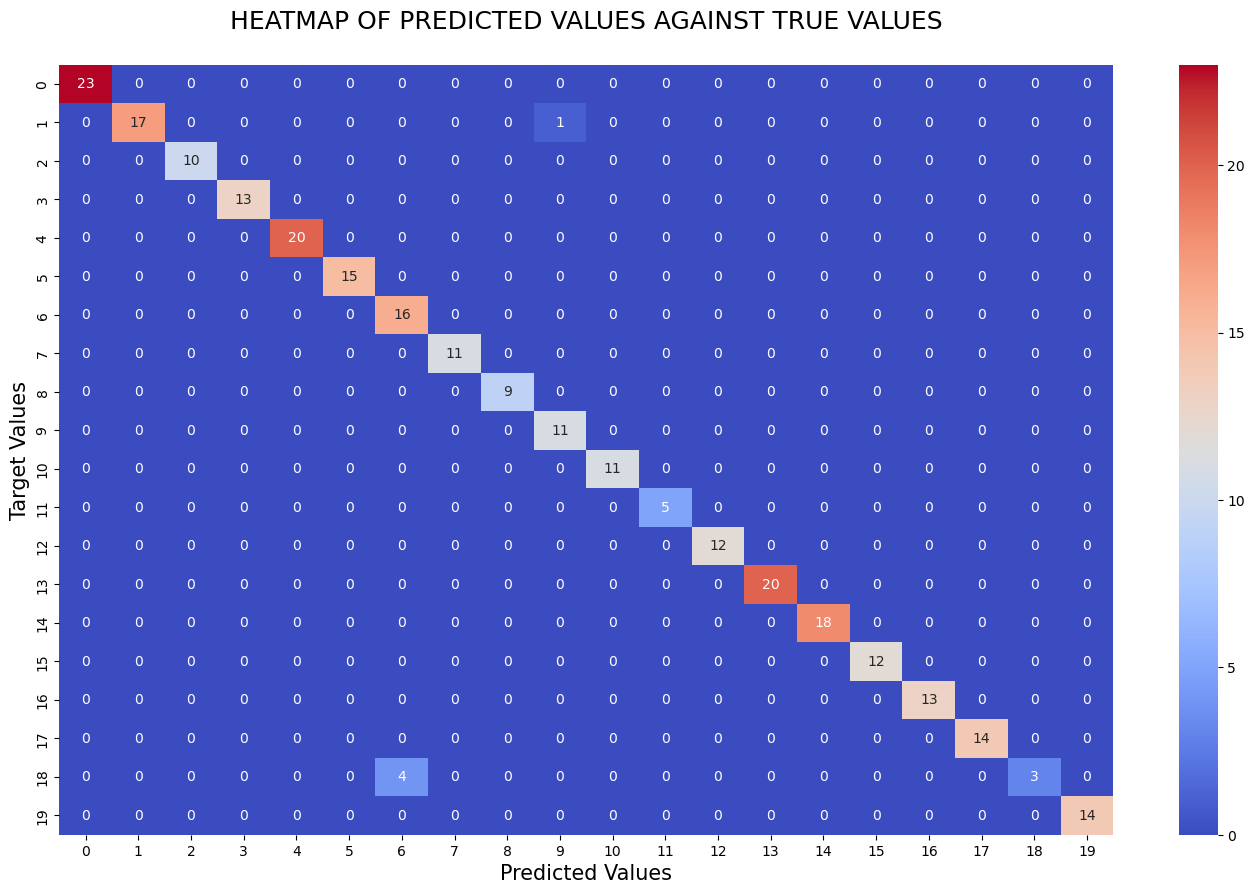

In [ ]:
plt.figure(figsize=(17,10))
sns.heatmap(cm,annot=True,cmap='coolwarm')
plt.title("HEATMAP OF PREDICTED VALUES AGAINST TRUE VALUES\n",fontsize=18)
plt.ylabel("Target Values",fontsize=15)
plt.xlabel("Predicted Values",fontsize=15)
plt.show()

##### A SUMMARY REPORT ON THE MODEL PERFORMANCE

In [ ]:
print(f"\t\tTHE CLASSIFICATION REPORT\n"+'_'*53)
print(cr)

		THE CLASSIFICATION REPORT
_____________________________________________________
              precision    recall  f1-score   support

      banana       1.00      1.00      1.00        23
   blackgram       1.00      0.94      0.97        18
    chickpea       1.00      1.00      1.00        10
     coconut       1.00      1.00      1.00        13
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        15
        jute       0.80      1.00      0.89        16
 kidneybeans       1.00      1.00      1.00        11
      lentil       1.00      1.00      1.00         9
       maize       0.92      1.00      0.96        11
       mango       1.00      1.00      1.00        11
   mothbeans       1.00      1.00      1.00         5
    mungbean       1.00      1.00      1.00        12
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        18
      papaya       1.00      1.00      1.00        12

### Saving the model using joblib

In [ ]:
import joblib as jb

In [ ]:
crop_model = jb.dump(mk_model,"crop-recommendation.pkl")

In [ ]:
crop_model = jb.load("crop-recommendation.pkl")

# Testing the model

In [ ]:
X_test[10:15]

,N,P,K,temperature,humidity,ph,rainfall
1303,114,8,50,24.746313,88.308663,6.581588,57.958261
1647,9,10,10,22.355105,93.522119,6.010392,101.516459
974,15,6,41,19.008707,88.837681,6.897368,108.679398
1168,33,31,34,31.329956,50.222876,5.421265,89.782162
1409,108,26,52,28.826290,94.267653,6.201798,26.238385


In [ ]:
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [ ]:
X_test[10:15], "________________" ,y_test[10:15]

(      N   P   K  temperature   humidity        ph    rainfall
 10  114   8  50    24.746313  88.308663  6.581588   57.958261
 11    9  10  10    22.355105  93.522119  6.010392  101.516459
 12   15   6  41    19.008707  88.837681  6.897368  108.679398
 13   33  31  34    31.329956  50.222876  5.421265   89.782162
 14  108  26  52    28.826290  94.267653  6.201798   26.238385,
 '________________',
 10     watermelon
 11         orange
 12    pomegranate
 13          mango
 14      muskmelon
 Name: label, dtype: object)

In [ ]:
crop_model.predict(X_test)[10]

'watermelon'

In [ ]:
crop_model.predict(X_test[10:15])

array(['watermelon', 'orange', 'pomegranate', 'mango', 'muskmelon'],
      dtype=object)

In [ ]:
y_test[10:15]

10     watermelon
11         orange
12    pomegranate
13          mango
14      muskmelon
Name: label, dtype: object

### WRITE MY REPORT ON THE CROP RECOMENDATION PREDICTION MODEL

##### This project is a machine learning based recomendation system.
##### Which uses the python programming language for various data cleaning, feature engineerng and its analysis
#####
#####